# Would buying favourites have made money?

The study finds that in US general elections favourites won more often than their prices said. If that is real, buying
favourites should have paid. This notebook checks that retrospectively: it "buys" the favourite of each contest at the
moment the study prices it, holds the position until the market settles, and counts the profit after the costs a
trader would actually have paid.

**What a bet is.** $100 on the favourite in every contest of a group, bought at the snapshot (17:00 in the easternmost
US time zone voting that day; 22:00 UTC on 3 November 2026). A contract pays $1 if the favourite wins and nothing
otherwise.

**What a bet costs:**
- **Kalshi:** the actual asking price at the snapshot, which is the midpoint plus half the gap between buy and sell
  prices. Kalshi's taker fee is added on top: 0.07 × price × (1 − price) per contract (fee schedule effective 7 July
  2026).
- **Polymarket:** only a recorded price is available, not a quote, so buying is assumed to cost 1 cent more; section 5
  varies this. Polymarket's politics taker fee, 0.04 × price × (1 − price) per share, is charged only from 30 March 2026.
  Its politics markets had no trading fee before that.

**Which contests:** every US contest that had a usable price at the snapshot. That includes the favourites above 95%,
which the study itself leaves out. The midterm runoff states are kept here, since a bet there still settles.

**Read the results with these limits in mind:**
- **In-sample:** the earlier elections are where the underconfidence was found, so profits there are not evidence. Only
  the midterms are out of sample.
- **Outcome-based selection:** contests enter the data only if they settled with one of the two listed candidates as
  the winner. That flatters favourites slightly. In the preliminary run, the 40 midterm races not yet settled lean
  towards ones where the favourite struggled.
- **Correlated bets:** bets on one night are not independent, because a national swing moves every race together.
  Intervals resample states, which handles states but not the night itself. Two general-election nights are two
  draws.
- **Fill size:** the Kalshi asking price is only good for the first few contracts. Order-book depth isn't recorded.
- **Idle money:** no interest is counted on money tied up until settlement. Kalshi's 2024 markets settled only in
  January 2025.
- **Strategy shopping:** trying many groups and keeping the best one finds profit by chance. Treat the price bands as
  description. Section 4, where every rule is fixed before the vote, is the honest test.

In [1]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

sys.path.insert(0, "../fit")
import midterm_test
import stretch

PRICES = Path("../calendar_and_prices/contest_prices.csv")
CALENDARS = [Path("../calendar_and_prices/contest_calendar.csv"), Path("../calendar_and_prices/midterm_calendar.csv")]
FIGURES, RESULTS = Path("figures"), Path("results")
FIGURES.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
STAGE = "final" if Path("../fit/results/midterm_test_final.csv").exists() else "preliminary"
OUT = f"backtest_{STAGE}"

STAKE = 100
KALSHI_TAKER = 0.07              # x price x (1 - price) per contract; Kalshi fee schedule effective 7 July 2026
POLYMARKET_TAKER = 0.04          # x price x (1 - price) per share; Polymarket politics taker fee
POLYMARKET_FEES_FROM = "2026-03-30"
POLYMARKET_HALF_SPREAD = 0.01    # Polymarket has a recorded price, not a quote: buying assumed to cost 1 cent more
TRADABLE = {"kept", "drop: favourite above 95% (scaled)"}
GROUPS = ["Earlier generals", "Earlier primaries", "Midterms 2026"]
PLATFORMS = ["Kalshi", "Polymarket"]
EDGES = [0.5, 0.7, 0.85, 0.9, 0.95, 0.98, 1.0001]
BANDS = ["50-70%", "70-85%", "85-90%", "90-95%", "95-98%", "98%+"]

MIDTERMS, GENERAL, PRIMARY, ALL = "#1baf7a", "#2a78d6", "#eb6834", "#0b0b0b"
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
COLOUR = {"Earlier generals": GENERAL, "Earlier primaries": PRIMARY, "Midterms 2026": MIDTERMS}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": INK_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110, "text.parse_math": False,
})


def save(fig, name):
    fig.savefig(FIGURES / f"{OUT}_{name}.png", dpi=220, bbox_inches="tight")
    fig.savefig(FIGURES / f"{OUT}_{name}.pdf", bbox_inches="tight")


def value_grid(ax, axis="y"):
    ax.grid(axis=axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

## 1. The bets

One row per contest and side. Each row records:
- the side's price as the study scales it, used to group bets into price bands;
- the price actually paid and the fee;
- whether that side won;
- the return on the stake;
- how many days the money was tied up until the market settled.

In [2]:
raw = pd.read_csv(PRICES, dtype={"contest_id": str})
raw = raw[(raw["country"] == "United States") & raw["reason"].isin(TRADABLE)].copy()
calendar = pd.concat([pd.read_csv(c, dtype={"contest_id": str}) for c in CALENDARS])
calendar = calendar.drop_duplicates(["platform", "contest_id"], keep="last").set_index(["platform", "contest_id"])


def side_bets(side):
    """Bets on the favourite (side="favourite") or the underdog (side="underdog") of every tradable contest."""
    a = (raw["p_a"] >= raw["p_b"]) if side == "favourite" else (raw["p_a"] < raw["p_b"])
    bets = pd.DataFrame({
        "platform": raw["platform"].to_numpy(), "contest_id": raw["contest_id"].to_numpy(),
        "title": raw["title"].to_numpy(), "state": raw["state"].fillna("none").to_numpy(),
        "election_key": raw["election_key"].to_numpy(), "kind": raw["kind"].to_numpy(),
        "candidate": np.where(a, raw["candidate_a"], raw["candidate_b"]),
        "price": np.where(a, raw["p_a"], raw["p_b"]),                # scaled, as in the study
        "quote": np.where(a, raw["price_a"], raw["price_b"]),        # the candidate's own price, not scaled
        "spread": np.where(a, raw["spread_a"], raw["spread_b"]),
        "won": np.where(a, raw["a_won"], 1 - raw["a_won"]).astype(int)})
    bets["day"] = bets["election_key"].str.split("-", n=1).str[1]
    bets["group"] = np.select([bets["election_key"] == midterm_test.TEST_DAY, bets["kind"] == "general"],
                              ["Midterms 2026", "Earlier generals"], "Earlier primaries")
    kalshi = bets["platform"] == "Kalshi"
    half_spread = np.where(kalshi, bets["spread"].fillna(0.02) / 2, POLYMARKET_HALF_SPREAD)
    bets["paid"] = np.minimum(bets["quote"] + half_spread, 1.0)
    rate = np.where(kalshi, KALSHI_TAKER, np.where(bets["day"] >= POLYMARKET_FEES_FROM, POLYMARKET_TAKER, 0.0))
    bets["fee"] = rate * bets["paid"] * (1 - bets["paid"])
    bets["all_in"] = bets["paid"] + bets["fee"]
    bets["return"] = bets["won"] / bets["all_in"] - 1
    bets["profit"] = STAKE * bets["return"]
    resolved = calendar.reindex(list(zip(bets["platform"], bets["contest_id"])))["market_resolved"].to_numpy()
    bets["days_held"] = (pd.Series(pd.to_datetime(resolved), index=bets.index) - pd.to_datetime(bets["day"])).dt.days
    bets["band"] = pd.cut(bets["price"], EDGES, labels=BANDS, right=False)
    unbuyable = bets["all_in"] >= 1
    print(f"{side}: {len(bets)} contests, {int(unbuyable.sum())} left out because buying cost $1 or more")
    return bets[~unbuyable].reset_index(drop=True)


favourites = side_bets("favourite")
underdogs = side_bets("underdog")
favourites.groupby(["platform", "group"]).agg(bets=("won", "size"), favourite_won=("won", "mean"),
                                               average_price=("price", "mean"), average_paid=("all_in", "mean"),
                                               median_days_held=("days_held", "median")).round(3)

favourite: 1487 contests, 133 left out because buying cost $1 or more
underdog: 1487 contests, 0 left out because buying cost $1 or more


bets  favourite_won  average_price  \
platform   group                                                   
Kalshi     Earlier generals    115          0.861          0.831   
           Earlier primaries   139          0.777          0.889   
           Midterms 2026       547          0.934          0.913   
Polymarket Earlier generals     98          0.959          0.901   
           Earlier primaries    36          0.833          0.887   
           Midterms 2026       419          0.952          0.915   

                              average_paid  median_days_held  
platform   group                                              
Kalshi     Earlier generals          0.852              62.0  
           Earlier primaries         0.915               1.0  
           Midterms 2026             0.922               1.0  
Polymarket Earlier generals          0.909               1.0  
           Earlier primaries         0.900               1.0  
           Midterms 2026             0.925               1.0

## 2. Buying every favourite

The columns, in plain words:
- **Return:** total profit divided by total stake. +2% means $2 back for every $100 bet, on top of the stake. Its 95%
  interval comes from resampling states, so the bets in a state go in or out together. **Share of resamples losing** is
  how often a resampled version of the same bets lost money overall.
- **Needed to break even:** the share of bets that had to win to cover the costs. With the same $100 on every bet, that
  is the harmonic mean of the all-in prices, which weights cheap bets more than a plain average does.
- **Won, 95% range:** the plausible range for the true win rate given these bets. If the bottom of that range sits below
  the break-even rate, the profit could be luck. This is the check to trust when nearly every favourite won, because
  resampling bets that all won can never produce a loss.
- **Upsets that would erase the profit:** profit divided by $100. A $100 bet on a favourite that loses costs about $100,
  so this is how many more upsets would have wiped the gain out.

Underdogs are shown alongside. If favourites are underpriced, underdogs are overpriced, and buying them should lose.
Underdog prices run from 1 to 50 cents, so a single break-even rate means little for them, and only the return is
shown.

In [3]:
rng = np.random.default_rng(stretch.SEED)


def summarise(part):
    states = part["state"].to_numpy()
    units = np.unique(states)
    rows = [np.flatnonzero(states == u) for u in units]
    profit = np.array([part["profit"].to_numpy()[r].sum() for r in rows])
    count = np.array([len(r) for r in rows])
    draws = rng.integers(0, len(units), (stretch.RESAMPLES, len(units)))
    boot = profit[draws].sum(1) / (STAKE * count[draws].sum(1))
    won_low, won_high = stretch.wilson(int(part["won"].sum()), len(part))
    return {"bets": len(part), "states": len(units), "average price": part["price"].mean(),
            "average paid, all in": part["all_in"].mean(),
            "needed to break even": len(part) / np.sum(1 / part["all_in"]),  # equal $ stakes: harmonic mean of costs
            "won": part["won"].mean(), "won, low": won_low, "won, high": won_high,
            "profit, $": part["profit"].sum(), "return": part["profit"].sum() / (STAKE * len(part)),
            "low": np.quantile(boot, 0.025), "high": np.quantile(boot, 0.975),
            "share of resamples losing": (boot < 0).mean(),
            "upsets that would erase the profit": part["profit"].sum() / STAKE if part["profit"].sum() > 0 else np.nan,
            "median days held": part["days_held"].median()}


rows = []
for side, bets in (("favourites", favourites), ("underdogs", underdogs)):
    for platform in PLATFORMS:
        for group in GROUPS:
            part = bets[(bets["platform"] == platform) & (bets["group"] == group)]
            row = {"platform": platform, "side": side, "group": group, **summarise(part)}
            if side == "underdogs":  # prices from 1 to 50 cents: one break-even rate means little
                row.update({"needed to break even": np.nan, "won, low": np.nan, "won, high": np.nan})
            rows.append(row)
every = pd.DataFrame(rows)
every.to_csv(RESULTS / f"{OUT}_every_contest.csv", index=False)
every.round(3).set_index(["platform", "side", "group"])

bets  states  average price  \
platform   side       group                                            
Kalshi     favourites Earlier generals    115      49          0.831   
                      Earlier primaries   139      37          0.889   
                      Midterms 2026       547      49          0.913   
Polymarket favourites Earlier generals     98      49          0.901   
                      Earlier primaries    36      19          0.887   
                      Midterms 2026       419      49          0.915   
Kalshi     underdogs  Earlier generals    137      51          0.145   
                      Earlier primaries   198      41          0.081   
                      Midterms 2026       547      49          0.087   
Polymarket underdogs  Earlier generals    105      52          0.093   
                      Earlier primaries    50      26          0.082   
                      Midterms 2026       450      49          0.079   

                                         average paid, all in  \
platform   side       group                                     
Kalshi     favourites Earlier generals                  0.852   
                      Earlier primaries                 0.915   
                      Midterms 2026                     0.922   
Polymarket favourites Earlier generals                  0.909   
                      Earlier primaries                 0.900   
                      Midterms 2026                     0.925   
Kalshi     underdogs  Earlier generals                  0.167   
                      Earlier primaries                 0.105   
                      Midterms 2026                     0.097   
Polymarket underdogs  Earlier generals                  0.103   
                      Earlier primaries                 0.095   
                      Midterms 2026                     0.092   

                                         needed to break even    won  \
platform   side       group                                            
Kalshi     favourites Earlier generals                  0.822  0.861   
                      Earlier primaries                 0.899  0.777   
                      Midterms 2026                     0.905  0.934   
Polymarket favourites Earlier generals                  0.889  0.959   
                      Earlier primaries                 0.885  0.833   
                      Midterms 2026                     0.906  0.952   
Kalshi     underdogs  Earlier generals                    NaN  0.117   
                      Earlier primaries                   NaN  0.157   
                      Midterms 2026                       NaN  0.066   
Polymarket underdogs  Earlier generals                    NaN  0.038   
                      Earlier primaries                   NaN  0.120   
                      Midterms 2026                       NaN  0.044   

                                         won, low  won, high  profit, $  \
platform   side       group                                               
Kalshi     favourites Earlier generals      0.786      0.913     78.438   
                      Earlier primaries     0.701      0.838  -2265.606   
                      Midterms 2026         0.910      0.952    480.642   
Polymarket favourites Earlier generals      0.900      0.984    678.697   
                      Earlier primaries     0.681      0.921   -352.975   
                      Midterms 2026         0.927      0.969   1256.313   
Kalshi     underdogs  Earlier generals        NaN        NaN  -8997.976   
                      Earlier primaries       NaN        NaN  -3543.929   
                      Midterms 2026           NaN        NaN -44046.103   
Polymarket underdogs  Earlier generals        NaN        NaN  -8893.166   
                      Earlier primaries       NaN        NaN  -2696.878   
                      Midterms 2026           NaN        NaN -39094.183   

                                         return    low   high

## 3. By the favourite's price

The same bets on favourites, split by how heavily favoured they were. The chart plots how many points more often
favourites won than they needed to break even, with the 95% range of the win rate: blue for earlier general elections,
orange for earlier primaries, aqua for the midterms. Above 0 means profit after costs. A range that reaches below 0 means
the profit could be luck. Bands with fewer than 5 bets are left off the chart but stay in the table.

Look at the high bands. At a 97-cent price, every favourite winning still leaves a range that reaches below break-even:
one upset wipes out about 30 wins.

These bands were chosen after looking at the data, and there are many of them, so one of them looking profitable is
expected by chance alone.

bets  states  average price  \
platform   group             band                                  
Kalshi     Earlier generals  50-70%    30      19          0.602   
                             70-85%    19      15          0.790   
                             85-90%     9       8          0.876   
                             90-95%    14      12          0.927   
                             95-98%    40      33          0.967   
                             98%+       3       3          0.987   
           Earlier primaries 50-70%    12       8          0.598   
                             70-85%    26      16          0.791   
                             85-90%    14      12          0.876   
                             90-95%    24      15          0.927   
                             95-98%    42      23          0.966   
                             98%+      21      11          0.988   
           Midterms 2026     50-70%    48      24          0.601   
                             70-85%    66      27          0.779   
                             85-90%    29      16          0.877   
                             90-95%    54      22          0.934   
                             95-98%   120      41          0.970   
                             98%+     230      47          0.986   
Polymarket Earlier generals  50-70%    11      11          0.618   
                             70-85%    15      11          0.803   
                             85-90%     8       7          0.887   
                             90-95%     7       7          0.929   
                             95-98%    23      18          0.968   
                             98%+      34      24          0.988   
           Earlier primaries 50-70%     3       3          0.625   
                             70-85%     7       5          0.796   
                             85-90%     5       4          0.872   
                             90-95%     8       7          0.931   
                             95-98%     9       6          0.969   
                             98%+       4       4          0.990   
           Midterms 2026     50-70%    34      24          0.597   
                             70-85%    47      24          0.778   
                             85-90%    26      15          0.876   
                             90-95%    45      22          0.932   
                             95-98%    89      37          0.970   
                             98%+     178      46          0.987   

                                     average paid, all in  \
platform   group             band                           
Kalshi     Earlier generals  50-70%                 0.631   
                             70-85%                 0.820   
                             85-90%                 0.894   
                             90-95%                 0.945   
                             95-98%                 0.982   
                             98%+                   0.993   
           Earlier primaries 50-70%                 0.656   
                             70-85%                 0.827   
                             85-90%                 0.907   
                             90-95%                 0.953   
                             95-98%                 0.986   
                             98%+                   0.996   
           Midterms 2026     50-70%                 0.634   
                             70-85%                 0.806   
                             85-90%                 0.894   
                             90-95%                 0.941   
                             95-98%                 0.974   
                             98%+                   0.988   
Polymarket Earlier generals  50-70%                 0.634   
                             70-85%                 0.812   
                             85-90%                 0.898   
                             90-95%              

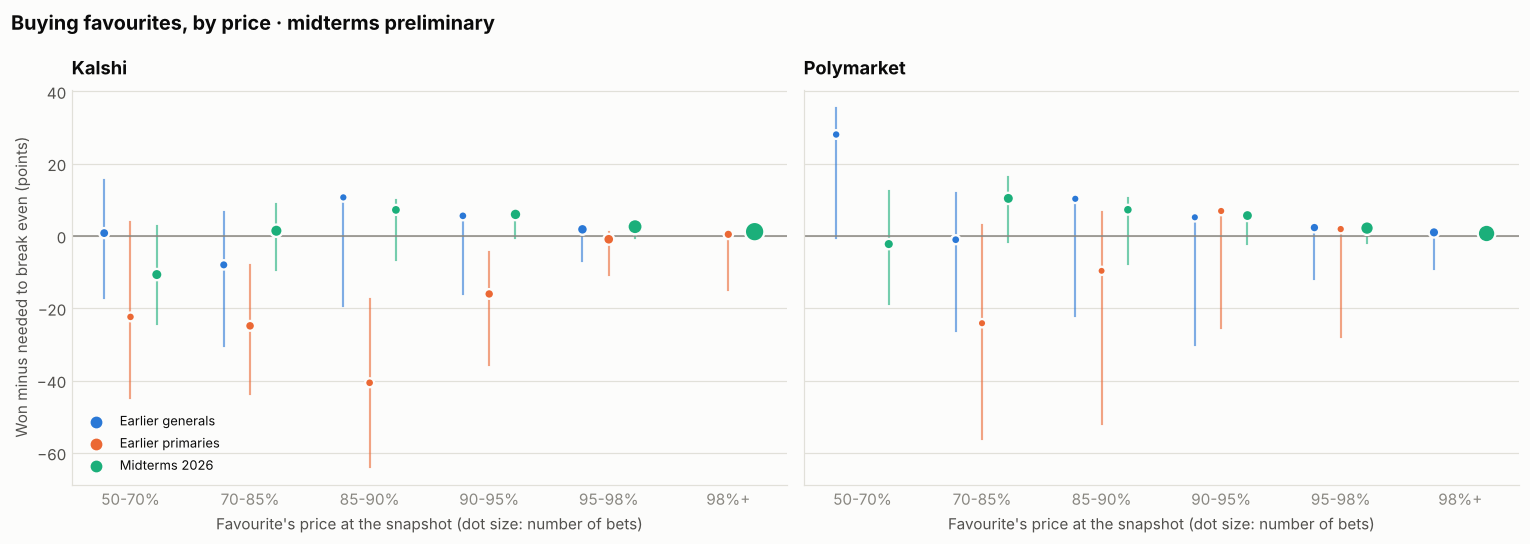

In [4]:
band_rows = []
for platform in PLATFORMS:
    for group in GROUPS:
        for band in BANDS:
            part = favourites[(favourites["platform"] == platform) & (favourites["group"] == group)
                              & (favourites["band"] == band)]
            if len(part):
                band_rows.append({"platform": platform, "group": group, "band": band, **summarise(part)})
bands = pd.DataFrame(band_rows)
bands.to_csv(RESULTS / f"{OUT}_price_bands.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
shift = {"Earlier generals": -0.22, "Earlier primaries": 0.0, "Midterms 2026": 0.22}
for ax, platform in zip(axes, PLATFORMS):
    for group in GROUPS:
        part = bands[(bands["platform"] == platform) & (bands["group"] == group) & (bands["bets"] >= 5)]
        x = np.array([BANDS.index(b) for b in part["band"]]) + shift[group]
        need = part["needed to break even"]
        for xi, (_, row) in zip(x, part.iterrows()):
            ax.plot([xi, xi], [100 * (row["won, low"] - row["needed to break even"]),
                               100 * (row["won, high"] - row["needed to break even"])],
                    color=COLOUR[group], linewidth=1.4, alpha=0.6)
        ax.scatter(x, 100 * (part["won"] - need), s=26 + part["bets"] * 0.6, color=COLOUR[group], zorder=3,
                   edgecolor=SURFACE, linewidth=1.5)
        ax.scatter([], [], s=45, color=COLOUR[group], label=group)
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.set_xticks(range(len(BANDS)), BANDS)
    ax.set_xlabel("Favourite's price at the snapshot (dot size: number of bets)")
    ax.set_title(platform, pad=10)
    value_grid(ax, "y")
axes[0].set_ylabel("Won minus needed to break even (points)")
axes[0].legend(loc="lower left", fontsize=8.5)
fig.suptitle(f"Buying favourites, by price · midterms {STAGE}", x=0.01, ha="left", fontsize=13, weight="bold")
fig.tight_layout()
save(fig, "price_bands")

bands.round(3).set_index(["platform", "group", "band"])

## 4. The honest test: rules fixed before the midterms

Everything a trader would have known before 3 November 2026, applied to the midterms only. The rule takes a stretch
learned before the vote: either the frozen 2024 value or the value from all earlier general elections. It turns each
favourite's price into a corrected chance, then buys only when that corrected chance beats the all-in cost by a
margin: 0, 2 or 5 cents. Nothing here is fitted on the midterms.

"Every favourite" is shown as the rule-free comparison. Six rules are tried per platform, so the best of them looks
better than it is. If one rule had to be named in advance, the plainest is the frozen 2024 value with no margin; read
the others as variations on it.

In [5]:
mid = favourites[favourites["group"] == "Midterms 2026"]
earlier = favourites[(favourites["group"] == "Earlier generals")]
walk_rows = []
for platform in PLATFORMS:
    base = mid[mid["platform"] == platform]
    known = stretch.load(platform)
    known = known[(known["kind"] == "General") & (known["election_key"] != midterm_test.TEST_DAY)]
    values = {"frozen 2024 value": midterm_test.BASELINE_B[platform],
              "earlier generals": stretch.fit(known["log_odds"], known["won"])}
    walk_rows.append({"platform": platform, "rule": "every favourite", "stretch": np.nan, "margin": np.nan,
                      **summarise(base)})
    for name, b in values.items():
        corrected = stretch.stretch(base["price"], b)
        for margin in (0.0, 0.02, 0.05):
            part = base[(corrected - base["all_in"]) > margin]
            if len(part):
                walk_rows.append({"platform": platform, "rule": f"{name}, margin {margin * 100:.0f} cents",
                                  "stretch": b, "margin": margin, **summarise(part)})
walk = pd.DataFrame(walk_rows)
walk.to_csv(RESULTS / f"{OUT}_rules_fixed_before.csv", index=False)
walk.round(3).set_index(["platform", "rule"])

stretch  margin  bets  states  \
platform   rule                                                               
Kalshi     every favourite                        NaN     NaN   547      49   
           frozen 2024 value, margin 0 cents    1.972    0.00   537      49   
           frozen 2024 value, margin 2 cents    1.972    0.02   267      44   
           frozen 2024 value, margin 5 cents    1.972    0.05   160      36   
           earlier generals, margin 0 cents     1.277    0.00   511      49   
           earlier generals, margin 2 cents     1.277    0.02   130      35   
           earlier generals, margin 5 cents     1.277    0.05     1       1   
Polymarket every favourite                        NaN     NaN   419      49   
           frozen 2024 value, margin 0 cents    1.828    0.00   413      49   
           frozen 2024 value, margin 2 cents    1.828    0.02   178      38   
           frozen 2024 value, margin 5 cents    1.828    0.05   112      34   
           earlier generals, margin 0 cents     1.608    0.00   410      49   
           earlier generals, margin 2 cents     1.608    0.02   170      38   
           earlier generals, margin 5 cents     1.608    0.05    87      29   

                                              average price  \
platform   rule                                               
Kalshi     every favourite                            0.913   
           frozen 2024 value, margin 0 cents          0.920   
           frozen 2024 value, margin 2 cents          0.865   
           frozen 2024 value, margin 5 cents          0.808   
           earlier generals, margin 0 cents           0.933   
           earlier generals, margin 2 cents           0.868   
           earlier generals, margin 5 cents           0.824   
Polymarket every favourite                            0.915   
           frozen 2024 value, margin 0 cents          0.921   
           frozen 2024 value, margin 2 cents          0.851   
           frozen 2024 value, margin 5 cents          0.795   
           earlier generals, margin 0 cents           0.922   
           earlier generals, margin 2 cents           0.845   
           earlier generals, margin 5 cents           0.801   

                                              average paid, all in  \
platform   rule                                                      
Kalshi     every favourite                                   0.922   
           frozen 2024 value, margin 0 cents                 0.929   
           frozen 2024 value, margin 2 cents                 0.880   
           frozen 2024 value, margin 5 cents                 0.829   
           earlier generals, margin 0 cents                  0.941   
           earlier generals, margin 2 cents                  0.880   
           earlier generals, margin 5 cents                  0.811   
Polymarket every favourite                                   0.925   
           frozen 2024 value, margin 0 cents                 0.931   
           frozen 2024 value, margin 2 cents                 0.863   
           frozen 2024 value, margin 5 cents                 0.809   
           earlier generals, margin 0 cents                  0.932   
           earlier generals, margin 2 cents                  0.858   
           earlier generals, margin 5 cents                  0.815   

                                              needed to break even    won  \
platform   rule                                                             
Kalshi     every favourite                                   0.905  0.934   
           frozen 2024 value, margin 0 cents                 0.916  0.942   
           frozen 2024 value, margin 2 cents                 0.865  0.895   
           frozen 2024 value, margin 5 cents                 0.817  0.831   
           earlier generals, margin 0 cents                  0.932  0.961   
           earlier generals, margin 2 cents                  0.874  0.946   
           earlier generals, margin

## 5. How much the costs matter

The midterm favourites and the earlier general-election favourites, bought in three ways:
- at the study's price with no costs at all;
- at the asking price without fees;
- at the full cost.

For Polymarket, the assumed extra cent is also replaced by 0, half a cent and 2 cents.

In [6]:
cost_rows = []
for platform in PLATFORMS:
    for group in ("Earlier generals", "Midterms 2026"):
        part = favourites[(favourites["platform"] == platform) & (favourites["group"] == group)]
        paid = part["paid"].to_numpy()
        fee = part["fee"].to_numpy()
        won = part["won"].to_numpy()
        quote = part["quote"].to_numpy()
        ways = {"study's price, no costs": quote, "asking price, no fee": paid, "asking price and fee (used above)": paid + fee}
        if platform == "Polymarket":
            rate = fee / np.maximum(paid * (1 - paid), 1e-12)
            for half in (0.0, 0.005, 0.02):
                p = np.minimum(quote + half, 1.0)
                ways[f"recorded price + {half * 100:g} cents, and fee"] = p + rate * p * (1 - p)
        ok = np.all([cost < 1 for cost in ways.values()], axis=0)  # the same bets under every assumption
        for way, cost in ways.items():
            cost_rows.append({"platform": platform, "group": group, "how bought": way, "bets": int(ok.sum()),
                              "return": float(np.mean(won[ok] / cost[ok] - 1))})
costs = pd.DataFrame(cost_rows)
costs.to_csv(RESULTS / f"{OUT}_costs.csv", index=False)
costs.round(4).set_index(["platform", "group", "how bought"])

bets  return
platform   group            how bought                                       
Kalshi     Earlier generals study's price, no costs               115  0.0329
                            asking price, no fee                  115  0.0176
                            asking price and fee (used above)     115  0.0068
           Midterms 2026    study's price, no costs               547  0.0202
                            asking price, no fee                  547  0.0143
                            asking price and fee (used above)     547  0.0088
Polymarket Earlier generals study's price, no costs                69  0.1095
                            asking price, no fee                   69  0.0962
                            asking price and fee (used above)      69  0.0962
                            recorded price + 0 cents, and fee      69  0.1095
                            recorded price + 0.5 cents, and fee    69  0.1028
                            recorded price + 2 cents, and fee      69  0.0832
           Midterms 2026    study's price, no costs               276  0.0600
                            asking price, no fee                  276  0.0477
                            asking price and fee (used above)     276  0.0429
                            recorded price + 0 cents, and fee     276  0.0547
                            recorded price + 0.5 cents, and fee   276  0.0488
                            recorded price + 2 cents, and fee     276  0.0314

## 6. Bet by bet over time

Running profit from $100 on every general-election favourite, in date order: the 2024 night, the smaller general
elections after it, and the midterms. The black line bets on every favourite, the grey line only on favourites at 90%
or more. Steps show how lumpy this is. Most of the profit or loss arrives on one or two nights, which is why one good
night says little about the next.

bets    won    profit  return
platform   day                                       
Kalshi     2024-11-05   97.0  0.876   339.319   0.035
           2025-04-01    1.0  1.000    15.151   0.152
           2025-11-04   10.0  1.000   112.682   0.113
           2025-12-02    1.0  1.000     9.202   0.092
           2025-12-09    1.0  1.000     1.898   0.019
           2026-03-24    2.0  0.000  -200.000  -1.000
           2026-04-16    1.0  1.000     0.186   0.002
           2026-05-19    2.0  0.000  -200.000  -1.000
           2026-11-03  547.0  0.934   480.642   0.009
Polymarket 2023-11-07    1.0  1.000    10.497   0.105
           2024-02-13    1.0  1.000    19.760   0.198
           2024-11-05   91.0  0.967   663.152   0.073
           2025-04-01    2.0  1.000    17.310   0.087
           2025-04-15    1.0  1.000    10.497   0.105
           2025-11-04    1.0  1.000    57.480   0.575
           2026-08-18    1.0  0.000  -100.000  -1.000
           2026-11-03  419.0  0.952  1256.313   0.030

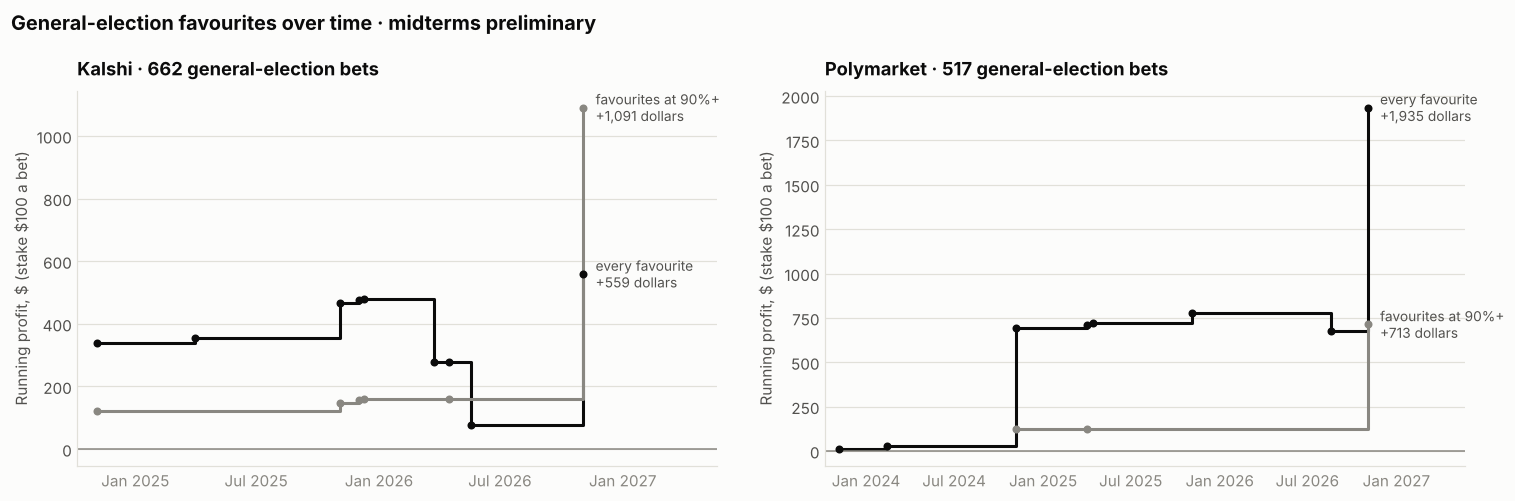

In [7]:
generals = favourites[favourites["group"] != "Earlier primaries"].copy()
generals["date"] = pd.to_datetime(generals["day"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, platform in zip(axes, PLATFORMS):
    part = generals[generals["platform"] == platform]
    for label, rule, colour in (("every favourite", part["price"] >= 0, INK), ("favourites at 90%+", part["price"] >= 0.9, MUTED)):
        by_day = part[rule].groupby("date")["profit"].sum().cumsum()
        ax.step(by_day.index, by_day.to_numpy(), where="post", color=colour, linewidth=2)
        ax.scatter(by_day.index, by_day.to_numpy(), color=colour, s=18, zorder=3)
        ax.annotate(f"{label}\n{by_day.iloc[-1]:+,.0f} dollars", (by_day.index[-1], by_day.iloc[-1]), xytext=(8, 0),
                    textcoords="offset points", ha="left", va="center", fontsize=9, color=INK_2)
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.set_xlim(part["date"].min() - pd.Timedelta(days=30), part["date"].max() + pd.Timedelta(days=200))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.set_title(f"{platform} · {int((part['price'] >= 0).sum())} general-election bets", pad=10)
    ax.set_ylabel("Running profit, $ (stake $100 a bet)")
    value_grid(ax, "y")
fig.suptitle(f"General-election favourites over time · midterms {STAGE}", x=0.01, ha="left", fontsize=13, weight="bold")
fig.tight_layout()
save(fig, "over_time")

nights = (generals.groupby(["platform", "day"])
          .apply(lambda d: pd.Series({"bets": len(d), "won": d["won"].mean(), "profit": d["profit"].sum(),
                                      "return": d["profit"].sum() / (STAKE * len(d))}), include_groups=False))
nights.to_csv(RESULTS / f"{OUT}_general_nights.csv")
nights.round(3)

## 7. Primaries: betting on the underdog (fitted to the results; not a test)

In the earlier primaries, favourites won less often than their prices said. So the obvious opposite bet is to buy the
underdog. **This is circular:** the overconfidence was found in these same contests, so this section can only show
how much money it would have made on data that already showed it. There are no midterm primaries to test it on; the
2028 primary season is where it could be tested properly.

Two versions:
- **By the favourite's price:** buy the underdog in every primary, grouped by how heavily the favourite was favoured.
- **By rule:** correct each price with the primaries' stretch, then buy the underdog when its corrected chance beats the
  all-in cost by a margin. This is done twice:
  - **With the stretch fitted on all primaries.** Fully circular.
  - **Leaving each election day out:** the stretch used on a day is fitted on the other primary days only. That is the
    fairest version this data allows, because no bet uses its own result.

  The rule is applied only where the study fits the stretch (favourites up to 95%); above that it would be
  extrapolating.

Underdogs at 1 to 5 cents are thinly traded. Buying $100 of them at the quoted price is optimistic.

In [8]:
dogs = underdogs[underdogs["group"] == "Earlier primaries"].copy()
dogs["favourite band"] = pd.cut(1 - dogs["price"], EDGES, labels=BANDS, right=False)
rows = []
for platform in PLATFORMS:
    mine = dogs[dogs["platform"] == platform]
    for band in BANDS:
        part = mine[mine["favourite band"] == band]
        if len(part):
            rows.append({"platform": platform, "favourite's price": band, **summarise(part)})
    rows.append({"platform": platform, "favourite's price": "all", **summarise(mine)})
primary_dogs = pd.DataFrame(rows)
primary_dogs.to_csv(RESULTS / f"{OUT}_primary_underdogs.csv", index=False)
COLUMNS = ["bets", "needed to break even", "won", "won, low", "won, high", "return", "low", "high", "profit, $"]
primary_dogs.set_index(["platform", "favourite's price"])[COLUMNS].round(3)

bets  needed to break even    won  won, low  \
platform   favourite's price                                                
Kalshi     50-70%               12                 0.440  0.583     0.320   
           70-85%               26                 0.240  0.423     0.255   
           85-90%               14                 0.155  0.500     0.268   
           90-95%               24                 0.099  0.208     0.092   
           95-98%               48                 0.053  0.021     0.004   
           98%+                 74                 0.013  0.000     0.000   
           all                 198                 0.028  0.157     0.113   
Polymarket 50-70%                3                 0.388  0.667     0.208   
           70-85%                7                 0.211  0.429     0.158   
           85-90%                5                 0.143  0.200     0.036   
           90-95%                8                 0.077  0.000     0.000   
           95-98%                9                 0.041  0.000     0.000   
           98%+                 18                 0.015  0.000     0.000   
           all                  50                 0.031  0.120     0.056   

                              won, high  return    low   high  profit, $  
platform   favourite's price                                              
Kalshi     50-70%                 0.807   0.305 -0.189  0.883    365.605  
           70-85%                 0.611   0.768 -0.084  1.717   1997.803  
           85-90%                 0.732   2.173  0.347  3.999   3042.855  
           90-95%                 0.405   0.919 -0.381  2.300   2205.236  
           95-98%                 0.109  -0.782 -1.000 -0.287  -3755.428  
           98%+                   0.049  -1.000 -1.000 -1.000  -7400.000  
           all                    0.214  -0.179 -0.486  0.092  -3543.929  
Polymarket 50-70%                 0.939   0.621 -1.000  1.535    186.201  
           70-85%                 0.750   0.573 -0.460  1.589    400.953  
           85-90%                 0.624   0.432 -1.000  4.370    215.968  
           90-95%                 0.324  -1.000 -1.000 -1.000   -800.000  
           95-98%                 0.299  -1.000 -1.000 -1.000   -900.000  
           98%+                   0.176  -1.000 -1.000 -1.000  -1800.000  
           all                    0.238  -0.539 -0.848 -0.122  -2696.878

In [9]:
rule_rows = []
for platform in PLATFORMS:
    known = stretch.load(platform)
    known = known[(known["kind"] == "Primary") & (known["election_key"] != midterm_test.TEST_DAY)]
    base = dogs[(dogs["platform"] == platform) & (1 - dogs["price"] <= 0.95)]
    b_all = stretch.fit(known["log_odds"], known["won"])
    b_without = {day: stretch.fit(known.loc[known["election_key"] != day, "log_odds"],
                                  known.loc[known["election_key"] != day, "won"]) for day in base["election_key"].unique()}
    rule_rows.append({"platform": platform, "rule": "every underdog, favourite up to 95%", **summarise(base)})
    for name, b in (("all primaries (circular)", np.full(len(base), b_all)),
                    ("other primary days only", base["election_key"].map(b_without).to_numpy())):
        corrected = 1 - stretch.stretch(1 - base["price"].to_numpy(), b)
        for margin in (0.0, 0.02, 0.05):
            part = base[(corrected - base["all_in"].to_numpy()) > margin]
            if len(part):
                rule_rows.append({"platform": platform, "rule": f"stretch from {name}, margin {margin * 100:.0f} cents",
                                  **summarise(part)})
primary_rules = pd.DataFrame(rule_rows)
primary_rules.to_csv(RESULTS / f"{OUT}_primary_underdog_rules.csv", index=False)
fitted = {p: stretch.load(p) for p in PLATFORMS}
print("primaries' stretch, all primary days: " + ", ".join(
    f"{p} {stretch.fit(d.loc[d['kind'] == 'Primary', 'log_odds'], d.loc[d['kind'] == 'Primary', 'won']):.2f}"
    for p, d in fitted.items()))
primary_rules.set_index(["platform", "rule"])[COLUMNS].round(3)

primaries' stretch, all primary days: Kalshi 0.32, Polymarket 0.88


bets  \
platform   rule                                                       
Kalshi     every underdog, favourite up to 95%                   78   
           stretch from all primaries (circular), margin 0...    72   
           stretch from all primaries (circular), margin 2...    72   
           stretch from all primaries (circular), margin 5...    70   
           stretch from other primary days only, margin 0 ...    72   
           stretch from other primary days only, margin 2 ...    72   
           stretch from other primary days only, margin 5 ...    70   
Polymarket every underdog, favourite up to 95%                   23   
           stretch from all primaries (circular), margin 0...    20   
           stretch from all primaries (circular), margin 2...     1   
           stretch from other primary days only, margin 0 ...    17   
           stretch from other primary days only, margin 2 ...    11   

                                                               needed to break even  \
platform   rule                                                                       
Kalshi     every underdog, favourite up to 95%                                0.159   
           stretch from all primaries (circular), margin 0...                 0.151   
           stretch from all primaries (circular), margin 2...                 0.151   
           stretch from all primaries (circular), margin 5...                 0.148   
           stretch from other primary days only, margin 0 ...                 0.151   
           stretch from other primary days only, margin 2 ...                 0.151   
           stretch from other primary days only, margin 5 ...                 0.148   
Polymarket every underdog, favourite up to 95%                                0.128   
           stretch from all primaries (circular), margin 0...                 0.116   
           stretch from all primaries (circular), margin 2...                 0.180   
           stretch from other primary days only, margin 0 ...                 0.109   
           stretch from other primary days only, margin 2 ...                 0.108   

                                                                 won  \
platform   rule                                                        
Kalshi     every underdog, favourite up to 95%                 0.397   
           stretch from all primaries (circular), margin 0...  0.389   
           stretch from all primaries (circular), margin 2...  0.389   
           stretch from all primaries (circular), margin 5...  0.371   
           stretch from other primary days only, margin 0 ...  0.389   
           stretch from other primary days only, margin 2 ...  0.389   
           stretch from other primary days only, margin 5 ...  0.371   
Polymarket every underdog, favourite up to 95%                 0.261   
           stretch from all primaries (circular), margin 0...  0.200   
           stretch from all primaries (circular), margin 2...  0.000   
           stretch from other primary days only, margin 0 ...  0.000   
           stretch from other primary days only, margin 2 ...  0.000   

                                                               won, low  \
platform   rule                                                           
Kalshi     every underdog, favourite up to 95%                    0.296   
           stretch from all primaries (circular), margin 0...     0.285   
           stretch from all primaries (circular), margin 2...     0.285   
           stretch from all primaries (circular), margin 5...     0.268   
           stretch from other primary days only, margin 0 ...     0.285   
           stretch from other primary days only, margin 2 ...     0.285   
           stretch from other primary days only, margin 5 ...     0.268   
Polymarket every underdog, favourite up to 95%                    0.125   
           stretch from all primaries (circular), margin 0...     0.081   
           stre

## Files

- `results/backtest_<stage>_every_contest.csv`: every favourite and every underdog, by group
- `results/backtest_<stage>_price_bands.csv`: favourites by price band
- `results/backtest_<stage>_rules_fixed_before.csv`: the out-of-sample midterm rules
- `results/backtest_<stage>_costs.csv`: how much the costs matter
- `results/backtest_<stage>_general_nights.csv`: profit on each general-election night
- `results/backtest_<stage>_primary_underdogs.csv` and `results/backtest_<stage>_primary_underdog_rules.csv`: the
  primaries' underdog bets (in-sample)
- figures `figures/backtest_<stage>_{price_bands, over_time}` as PNG and PDF

The notebook reads the same price table as the study and changes nothing in it. After the final midterm run, run it
again for a `final` set.